# Train: Logistic Regression on the 200k Dataset (CMU + Synthetic)

## 1. Introduction

This notebook trains the logistic regression model using the 200k training dataset created in `01_prepare_synthetic`. The test set is **not opened** here, so it remains available for final evaluation.

The workflow is:

1. Load the training data and define the features (`X`) and target (`y`).
2. Train baseline models for comparison.
3. Compare candidate feature sets using training data only.
4. Train the logistic regression model and examine its training performance.
5. Estimate generalization performance using 5-fold cross-validation.
6. Select a decision threshold for the target Recall of 85%.
7. Save the trained model, feature list, and threshold.

### Handling synthetic data during cross-validation

Ordinary cross-validation could produce overly optimistic results if synthetic rows derived from a real person appear in training while that person appears in validation. To reduce this risk:

- **Validate on real rows only:** Synthetic rows are not used to score the model.
- **Split real rows first:** The real training data is divided into folds before synthetic rows are generated.
- **Generate synthetic rows within each fold:** Synthetic rows are created using only that fold's training portion.

This allows each fold to evaluate the model on real people who were not included in that fold's training data.

### Interpreting metrics on a 50/50 scale

The real training data has more people without reported diabetes than people with reported diabetes. For consistent comparison with the 70k model, metrics are reported on a **50/50 class scale**.

- **Recall, specificity, and ROC AUC** are calculated from the real validation predictions and do not depend directly on class prevalence.
- **Accuracy, precision, and F1** are calculated or adjusted to represent an equal number of people in each class.

These 50/50-scale metrics support model comparison, but precision and accuracy may differ in a population with a different diabetes prevalence.

**Source table:** `diabetes_cmu_synth_train`  
**Output:** A saved model file

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
import sys
import sklearn

# statsmodels: p-values for the feature selection
import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sqlalchemy import create_engine, text

# Our own helper file in the 09_utils folder
# The notebook's current working directory is:
# notebooks/07_modeling_cmu(+synthetic200k)
# so ../09_utils points to:
# notebooks/09_utils
UTILS_PATH = Path("../09_utils").resolve()
sys.path.insert(0, str(UTILS_PATH))

from synth_utils import generate_synthetic

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

TRAIN_TABLE = "diabetes_cmu_synth_train"
TARGET = "Diabetes_binary"
RANDOM_STATE = 42
TARGET_RECALL = 0.85              # PLACEHOLDER: same working goal as the 70k model (the group should confirm it)
REAL_PREVALENCE = 0.14            # about 14% of the surveyed people had diabetes
MODEL_PATH = Path("../../application/models/logreg_200k.joblib")

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Libraries imported and database connection successful.")
print("synth_utils path:", UTILS_PATH)
print("synth_utils found:", (UTILS_PATH / "synth_utils.py").exists())

Libraries imported and database connection successful.
synth_utils path: C:\Users\PLP\Documents\dsf-final-project-setc\notebooks\09_utils
synth_utils found: True


## 3. Load the Training Set

In [21]:
train_df = pd.read_sql(f"SELECT * FROM {TRAIN_TABLE}", con=engine)

all_features = [c for c in train_df.columns if c not in (TARGET, "is_synthetic")]
X_train, y_train = train_df[all_features], train_df[TARGET]

# The real rows only (used for cross-validation and for the p-values)
real_df = train_df[train_df["is_synthetic"] == 0].reset_index(drop=True)
X_real, y_real = real_df[all_features], real_df[TARGET]

NON_BINARY = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]

summary = pd.DataFrame({
    "Item": ["Training rows", "Features", "No diabetes (0)", "Diabetes (1)",
             "Real rows", "Real: no diabetes", "Real: diabetes", "Synthetic rows (all diabetes)"],
    "Value": [f"{len(train_df):,}", len(all_features), f"{(y_train == 0).sum():,}", f"{(y_train == 1).sum():,}",
              f"{len(real_df):,}", f"{(y_real == 0).sum():,}", f"{(y_real == 1).sum():,}",
              f"{int(train_df['is_synthetic'].sum()):,}"],
})
display(summary.style.hide(axis="index"))

print(f"Training set '{TRAIN_TABLE}' loaded successfully.")

Item,Value
Training rows,"200,000"
Features,21
No diabetes (0),"100,000"
Diabetes (1),"100,000"
Real rows,"128,078"
Real: no diabetes,"100,000"
Real: diabetes,"28,078"
Synthetic rows (all diabetes),"71,922"


Training set 'diabetes_cmu_synth_train' loaded successfully.


## 4. Tools Used in This Notebook

- **Cross-validation folds (real rows only, synthetic rows made inside each fold).** The folds are built **once** and reused for every model, so all models are scored on exactly the same people.
- **Model builder:** the same as for the 70k model: logistic regression with no penalty, the 7 non-binary features standardized inside the model.
- **Metrics on a 50/50 scale:** Recall, specificity and ROC AUC are measured directly. Precision, F1 and accuracy are computed from Recall and the false alarm rate as if the people with and without diabetes were equally many.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_logreg(cols):
    """Logistic regression (no penalty) with scaling of the non-binary columns done inside the model."""
    scale = [c for c in cols if c in NON_BINARY]
    prep = ColumnTransformer([("scale", StandardScaler(), scale)],
                             remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", LogisticRegression(C=np.inf, max_iter=2000))])

def scores_5050(y, proba, t=0.5):
    """Metrics for one set of rows, with precision/F1/accuracy on a 50/50 scale."""
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    tpr, tnr = tp / (tp + fn), tn / (tn + fp)
    prec = tpr / (tpr + (1 - tnr)) if (tpr + (1 - tnr)) > 0 else 0.0
    f1 = 2 * prec * tpr / (prec + tpr) if (prec + tpr) > 0 else 0.0
    return {"Accuracy": (tpr + tnr) / 2, "Recall": tpr, "Specificity": tnr,
            "Precision": prec, "F1": f1, "ROC AUC": roc_auc_score(y, proba)}

# --- Build the 5 folds ONCE: split the real rows, then create synthetic rows from each training part ---
folds = []
for i, (tr, va) in enumerate(cv.split(X_real, y_real)):
    X_tr, y_tr = X_real.iloc[tr], y_real.iloc[tr]
    X_va, y_va = X_real.iloc[va], y_real.iloc[va]
    n_new = int((y_tr == 0).sum() - (y_tr == 1).sum())                 # make the training part 50/50
    syn = generate_synthetic(X_tr[y_tr == 1], n_new, seed=RANDOM_STATE + i, avoid=X_va)
    folds.append({
        "X_tr": pd.concat([X_tr, syn], ignore_index=True),
        "y_tr": pd.concat([y_tr, pd.Series(1, index=range(n_new))], ignore_index=True),
        "X_va": X_va, "y_va": y_va,
    })

def cv_scores(build_model, cols):
    """Mean and standard deviation of every metric over the 5 folds (validation rows are real)."""
    rows = []
    for f in folds:
        model = build_model(cols).fit(f["X_tr"][cols], f["y_tr"])
        rows.append(scores_5050(f["y_va"], model.predict_proba(f["X_va"][cols])[:, 1]))
    res = pd.DataFrame(rows)
    return {m: (res[m].mean(), res[m].std()) for m in res.columns}

fold_info = pd.DataFrame({
    "Fold": range(1, 6),
    "Training rows (real + synthetic)": [f"{len(f['X_tr']):,}" for f in folds],
    "of which synthetic": [f"{len(f['X_tr']) - (len(X_real) - len(f['X_va'])):,}" for f in folds],
    "Validation rows (all real)": [f"{len(f['X_va']):,}" for f in folds],
    "Validation: % diabetes": [f"{f['y_va'].mean() * 100:.1f}%" for f in folds],
})
display(fold_info.style.hide(axis="index"))

print("Tools defined and the 5 cross-validation folds built.")

Fold,Training rows (real + synthetic),of which synthetic,Validation rows (all real),Validation: % diabetes
1,"160,000","57,538","25,616",21.9%
2,"160,000","57,538","25,616",21.9%
3,"160,000","57,538","25,616",21.9%
4,"160,000","57,537","25,615",21.9%
5,"160,000","57,537","25,615",21.9%


Tools defined and the 5 cross-validation folds built.


## 5. Baseline Models

The same three baselines as for the 70k model. They are trained on each fold's training part and scored on the real validation people. All three use no information from the features, so every one should sit at chance.

In [23]:
baselines = {
    "Baseline: always no diabetes": lambda cols: DummyClassifier(strategy="constant", constant=0),
    "Baseline: flag everybody": lambda cols: DummyClassifier(strategy="constant", constant=1),
    "Baseline: random guess": lambda cols: DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

baseline_cv = {name: cv_scores(b, all_features) for name, b in baselines.items()}

table = pd.DataFrame({
    name: {m: f"{mean:.3f} ± {sd:.3f}" for m, (mean, sd) in scores.items()}
    for name, scores in baseline_cv.items()
}).T
display(table)

print("Baselines trained successfully.")

,Accuracy,Recall,Specificity,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Baseline: flag everybody,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.667 ± 0.000,0.500 ± 0.000
Baseline: random guess,0.502 ± 0.004,0.501 ± 0.006,0.503 ± 0.002,0.502 ± 0.004,0.502 ± 0.005,0.502 ± 0.004


Baselines trained successfully.


### Interpretation

- **Always predict no diabetes:** Achieves 0.500 accuracy and 1.000 specificity, but has 0.000 recall because it misses every diabetes case.
- **Flag everybody:** Achieves 1.000 recall but 0.000 specificity, meaning every person is flagged regardless of their actual status.
- **Random guess:** Produces approximately 0.502 across most metrics, showing performance close to chance.
- **Purpose of these baselines:** They provide reference points for evaluating whether the trained logistic regression model offers meaningful predictive value.

In [24]:
# --- p-value rule, fitted on the REAL training rows only ---
scaled = X_real.astype(float).copy()
scaled[NON_BINARY] = StandardScaler().fit_transform(scaled[NON_BINARY])
sm_fit = sm.Logit(y_real, sm.add_constant(scaled)).fit(disp=False)
p_values = sm_fit.pvalues.drop("const")

p_table = pd.DataFrame({
    "p-value (real training rows)": p_values.round(3),
    "Kept by the rule (p <= 0.05)": p_values <= 0.05,
}).sort_values("p-value (real training rows)", ascending=False)
display(p_table)

# --- Candidate feature sets ---
feature_sets = {
    "All features (21)": all_features,
    "Without healthcare access (18)": [f for f in all_features if f not in ["CholCheck", "AnyHealthcare", "NoDocbcCost"]],
    "p-value rule (real training rows)": [f for f in all_features if p_values[f] <= 0.05],
}
print("Dropped by the p-value rule:", [f for f in all_features if p_values[f] > 0.05])

# --- Score every candidate with the 5 folds (ROC AUC) ---
rows = []
for name, cols in feature_sets.items():
    s = cv_scores(make_logreg, cols)["ROC AUC"]
    rows.append({"Feature set": name, "Features": len(cols), "ROC AUC (mean)": s[0], "ROC AUC (std)": s[1]})
fs = pd.DataFrame(rows)

# --- Selection rule: the smallest set within one standard deviation of the best ---
best = fs.loc[fs["ROC AUC (mean)"].idxmax()]
within = fs[fs["ROC AUC (mean)"] >= best["ROC AUC (mean)"] - best["ROC AUC (std)"]]
chosen_name = within.sort_values(["Features", "ROC AUC (mean)"], ascending=[True, False]).iloc[0]["Feature set"]
fs["Within 1 SD of the best"] = fs["Feature set"].isin(within["Feature set"])
fs["Chosen"] = fs["Feature set"] == chosen_name
display(fs.round(4).style.hide(axis="index"))

# Final project decision:
# Both the 70k and 200k models must use the same predictors.
FEATURES = [
    "HighBP",
    "HighChol",
    "BMI",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "HvyAlcoholConsump",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income",
]

assert len(FEATURES) == 16
assert "CholCheck" not in FEATURES
assert "AnyHealthcare" not in FEATURES
assert "NoDocbcCost" not in FEATURES

print(f"Final feature set: {len(FEATURES)} features")
print("Features:", ", ".join(FEATURES))

,p-value (real training rows),Kept by the rule (p <= 0.05)
Veggies,0.463,False
NoDocbcCost,0.243,False
Smoker,0.178,False
Fruits,0.080,False
PhysActivity,0.016,True
Education,0.006,True
AnyHealthcare,0.002,True
HighChol,0.000,True
HighBP,0.000,True
Stroke,0.000,True


Dropped by the p-value rule: ['Smoker', 'Fruits', 'Veggies', 'NoDocbcCost']


Feature set,Features,ROC AUC (mean),ROC AUC (std),Within 1 SD of the best,Chosen
All features (21),21,0.807900,0.006200,True,False
Without healthcare access (18),18,0.806400,0.006300,True,False
p-value rule (real training rows),17,0.807900,0.006300,True,True


Final feature set: 16 features
Features: HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income


### Interpretation

- **P-value screening:** The rule \(p \leq 0.05\) retains 17 features based on their statistical association with the target in the real training rows. Four features are excluded: `Smoker`, `Fruits`, `Veggies`, and `NoDocbcCost`.
- **Cross-validation comparison:** All three candidate feature sets achieve similar mean ROC AUC scores, ranging from 0.8064 to 0.8079. Each is within one standard deviation of the best score, indicating little difference in cross-validation performance.
- **Selected candidate:** The p-value-rule feature set is selected because it achieves a mean ROC AUC of 0.8079 while reducing the number of features from 21 to 17.
- **Final feature set:** The model ultimately uses 16 features to maintain consistency with the 70k model for a fair comparison. This final set includes `Fruits`, even though it did not pass the p-value rule.
- **Important distinction:** Statistical significance alone does not determine whether a feature improves predictive performance. The final 16-feature set is chosen for consistency between datasets, not because the p-value rule selected exactly those 16 features.

## 7. Train the Logistic Regression

We fit the model on the whole 200k training set (real + synthetic) with the chosen features: **fit**, then **predict**, then **score**. The training score is reported twice: on all 200,000 rows, and on the **real rows only**, which is the fairer one because the model has seen the synthetic rows' parents anyway.

In [25]:
logreg = make_logreg(FEATURES)
logreg.fit(X_train[FEATURES], y_train)

proba_all = logreg.predict_proba(X_train[FEATURES])[:, 1]
is_real = (train_df["is_synthetic"] == 0).to_numpy()

logreg_train = {"All 200,000 rows": scores_5050(y_train, proba_all),
                "Real rows only": scores_5050(y_train[is_real], proba_all[is_real])}
display(pd.DataFrame(logreg_train).round(3))

# Odds ratios of the final model
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
odds = pd.DataFrame({"Odds ratio": np.exp(coefs)}).sort_values("Odds ratio", ascending=False).round(3)
display(odds)

print("Logistic regression trained successfully.")

,"All 200,000 rows",Real rows only
Accuracy,0.745,0.731
Recall,0.763,0.736
Specificity,0.727,0.727
Precision,0.737,0.729
F1,0.750,0.733
ROC AUC,0.821,0.807


,Odds ratio
HighBP,2.140
GenHlth,1.904
HighChol,1.831
BMI,1.718
Age,1.501
Sex,1.283
HeartDiseaseorAttack,1.204
DiffWalk,1.158
Stroke,1.051
MentHlth,0.987


Logistic regression trained successfully.


### Interpretation

- **Training performance:** The model performs better when evaluated on all 200,000 rows, with a ROC AUC of 0.821, compared with 0.807 on real rows only.
- **Real-row evaluation:** Accuracy is 0.731, Recall is 0.736, and F1 is 0.733. These results provide a more realistic check of performance on real observations than evaluation that includes synthetic rows.
- **Important comparison:** The higher scores on all rows may reflect the synthetic data's influence, so real-row results are more useful when assessing generalization.
- **Largest odds ratios:** `HighBP` (2.140), `GenHlth` (1.904), and `HighChol` (1.831) have the largest reported odds ratios in this table.
- **Lower odds ratios:** `HvyAlcoholConsump` has the lowest odds ratio (0.375), followed by `Income` (0.886). These are model associations, not proof of causation.
- **Overall:** Logistic regression trained successfully using the final 16-feature set.

## 8. Model Comparison: Logistic Regression Against the Baselines

The cross-validation scores are honest: real validation people, synthetic rows made inside each fold. We compare them with the training scores to check for overfitting.

In [26]:
logreg_cv = cv_scores(make_logreg, FEATURES)

all_cv = {**baseline_cv, "Logistic regression": logreg_cv}
cv_table = pd.DataFrame({
    name: {m: f"{mean:.3f} ± {sd:.3f}" for m, (mean, sd) in scores.items()}
    for name, scores in all_cv.items()
}).T
print("Cross-validation scores (real validation people, 50/50 scale):")
display(cv_table)

gap = pd.DataFrame({
    "Training score (real rows)": pd.Series(logreg_train["Real rows only"]),
    "Cross-validation score": pd.Series({m: v[0] for m, v in logreg_cv.items()}),
})
gap["Gap (training - CV)"] = gap["Training score (real rows)"] - gap["Cross-validation score"]
print("Logistic regression: training vs cross-validation")
display(gap.round(4))

beats = all(logreg_cv["ROC AUC"][0] > b["ROC AUC"][0] for b in baseline_cv.values())
print("Logistic regression beats every baseline on ROC AUC:", beats)

Cross-validation scores (real validation people, 50/50 scale):


,Accuracy,Recall,Specificity,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Baseline: flag everybody,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.667 ± 0.000,0.500 ± 0.000
Baseline: random guess,0.502 ± 0.004,0.501 ± 0.006,0.503 ± 0.002,0.502 ± 0.004,0.502 ± 0.005,0.502 ± 0.004
Logistic regression,0.731 ± 0.005,0.736 ± 0.009,0.727 ± 0.004,0.729 ± 0.004,0.733 ± 0.006,0.806 ± 0.006


Logistic regression: training vs cross-validation


,Training score (real rows),Cross-validation score,Gap (training - CV)
Accuracy,0.7314,0.7313,0.0001
Recall,0.7357,0.7361,-0.0004
Specificity,0.7271,0.7265,0.0005
Precision,0.7294,0.7291,0.0003
F1,0.7326,0.7326,-0.0000
ROC AUC,0.8066,0.8064,0.0002


Logistic regression beats every baseline on ROC AUC: True


### Interpretation

- **Baseline comparison:** Logistic regression outperforms all three baselines, achieving a cross-validation ROC AUC of 0.806 compared with approximately 0.500–0.502 for the baselines.
- **Cross-validation performance:** The model achieves 0.736 Recall, 0.727 Specificity, 0.729 Precision, and 0.733 F1 on the 50/50 class scale.
- **Training vs. cross-validation:** The metrics are nearly identical, with gaps close to zero across all measures. This suggests consistent performance between the real training rows and the cross-validation folds.
- **Generalization:** The small training-to-cross-validation gaps provide little evidence of overfitting based on these metrics, although they do not guarantee performance on new populations.
- **Overall:** Logistic regression provides meaningful predictive value beyond the baseline models and maintains consistent cross-validation performance.
## 9. Choosing the Decision Threshold for Recall

Same idea as for the 70k model: pick the **highest threshold that still reaches the Recall goal**, using predictions that come from models that did not see the person (**out-of-fold** predictions). Here the out-of-fold predictions are for the **real** validation people of the 5 folds, so the threshold is not influenced by synthetic rows.

Because Recall and the false alarm rate do not depend on the class mix, they can be read directly from these real people. The precision at the real prevalence (about 14%) is estimated from them, as before. It is an approximation, because the labels are self-reported diagnoses.

Setting,Threshold,Recall,Specificity,Precision (50/50 scale),Precision at 14% prevalence,Share of people flagged at 14%
Default threshold,0.500000,0.736000,0.727000,0.729000,0.305000,0.338000
Recall goal 70%,0.533000,0.700000,0.755000,0.741000,0.317000,0.309000
Recall goal 80%,0.434000,0.800000,0.666000,0.705000,0.280000,0.400000
Recall goal 85%,0.376000,0.850000,0.605000,0.683000,0.260000,0.458000
Recall goal 90%,0.308000,0.900000,0.526000,0.655000,0.236000,0.534000


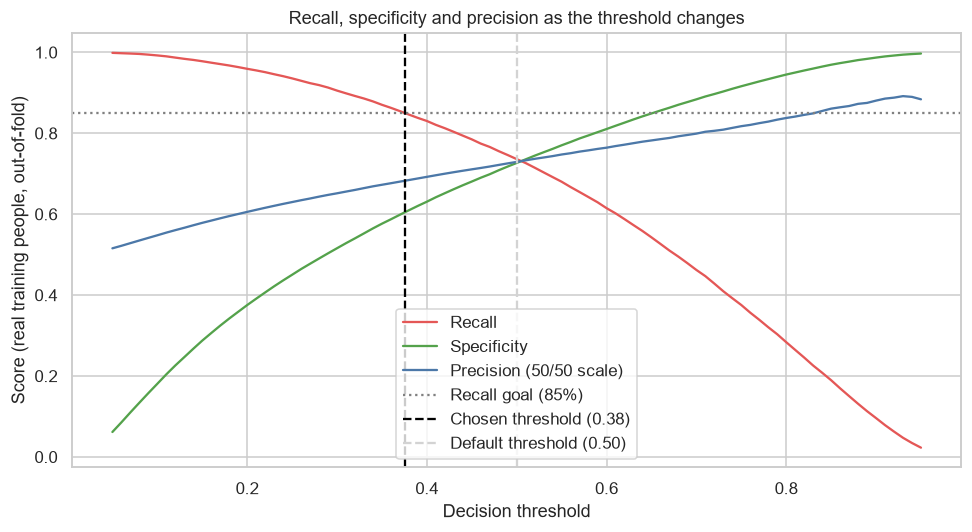

Chosen threshold: 0.376 (reaches a Recall of at least 85% out-of-fold).


In [27]:
# Out-of-fold probabilities for every real training person
oof_p, oof_y = [], []
for f in folds:
    model = make_logreg(FEATURES).fit(f["X_tr"][FEATURES], f["y_tr"])
    oof_p.append(model.predict_proba(f["X_va"][FEATURES])[:, 1])
    oof_y.append(f["y_va"].to_numpy())
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)

def threshold_for(goal):
    """Highest threshold at which at least `goal` of the people with diabetes are flagged."""
    return float(np.quantile(oof_p[oof_y == 1], 1 - goal, method="lower"))

def metrics_at(t):
    flagged = oof_p >= t
    tpr, fpr = flagged[oof_y == 1].mean(), flagged[oof_y == 0].mean()
    flagged_real = tpr * REAL_PREVALENCE + fpr * (1 - REAL_PREVALENCE)
    return {"Recall": tpr, "Specificity": 1 - fpr,
            "Precision (50/50 scale)": tpr / (tpr + fpr),
            f"Precision at {REAL_PREVALENCE:.0%} prevalence": tpr * REAL_PREVALENCE / flagged_real,
            f"Share of people flagged at {REAL_PREVALENCE:.0%}": flagged_real}

rows = [{"Setting": "Default threshold", "Threshold": 0.5, **metrics_at(0.5)}]
for goal in [0.70, 0.80, 0.85, 0.90]:
    t = threshold_for(goal)
    rows.append({"Setting": f"Recall goal {goal:.0%}", "Threshold": t, **metrics_at(t)})
goals = pd.DataFrame(rows)
display(goals.round(3).style.hide(axis="index"))

chosen_threshold = threshold_for(TARGET_RECALL)

# Chart: recall, specificity and precision as the threshold changes
grid = np.linspace(0.05, 0.95, 91)
curve = pd.DataFrame([metrics_at(t) for t in grid], index=grid)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(grid, curve["Recall"], label="Recall", color="#E45756")
ax.plot(grid, curve["Specificity"], label="Specificity", color="#54A24B")
ax.plot(grid, curve["Precision (50/50 scale)"], label="Precision (50/50 scale)", color="#4C78A8")
ax.axhline(TARGET_RECALL, ls=":", color="grey", label=f"Recall goal ({TARGET_RECALL:.0%})")
ax.axvline(chosen_threshold, ls="--", color="black", label=f"Chosen threshold ({chosen_threshold:.2f})")
ax.axvline(0.5, ls="--", color="lightgrey", label="Default threshold (0.50)")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score (real training people, out-of-fold)")
ax.set_title("Recall, specificity and precision as the threshold changes")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Chosen threshold: {chosen_threshold:.3f} (reaches a Recall of at least {TARGET_RECALL:.0%} out-of-fold).")

### Interpretation

- **Default threshold (0.50):** Achieves 0.736 Recall and 0.727 Specificity, providing a balanced starting point for classification.
- **Threshold selection:** The chosen threshold of **0.376** reaches the target Recall of at least 85% using out-of-fold predictions.
- **Recall-specificity trade-off:** As the recall target increases, the threshold decreases. Recall improves, but specificity declines, meaning more people without reported diabetes are flagged.
- **Precision at 14% prevalence:** The estimated precision decreases from 0.305 at the default threshold to 0.260 at the chosen threshold. This reflects the effect of assuming a lower diabetes prevalence than the 50/50 evaluation scale.
- **Screening implications:** At the chosen threshold, approximately 45.8% of people would be flagged under the 14% prevalence assumption. This may help identify more potential cases, but it also increases follow-up workload.
- **Overall:** The threshold is selected to prioritize finding more potential diabetes cases, not to maximize accuracy or minimize false positives.

In [28]:
bundle = {
    "model": logreg,
    "features": FEATURES,
    "threshold": chosen_threshold,
    "target_recall": TARGET_RECALL,
    "feature_set_name": "shared_16_features",
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "training_data": "200k: 100,000 no diabetes (real) + 100,000 diabetes (real + synthetic)",
}
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(bundle, MODEL_PATH)

# Verify: reload the file and check that it gives identical predictions
reloaded = joblib.load(MODEL_PATH)
same = np.allclose(reloaded["model"].predict_proba(X_train[FEATURES])[:, 1],
                   logreg.predict_proba(X_train[FEATURES])[:, 1])

saved = pd.DataFrame({
    "Item": ["File", "Features saved", "Threshold saved", "scikit-learn version", "Reloaded model gives identical predictions"],
    "Value": [str(MODEL_PATH), len(reloaded["features"]), round(reloaded["threshold"], 3),
              reloaded["sklearn_version"], same],
})
display(saved.style.hide(axis="index"))

print("Model saved successfully.")

Item,Value
File,..\..\application\models\logreg_200k.joblib
Features saved,16
Threshold saved,0.376000
scikit-learn version,1.9.1
Reloaded model gives identical predictions,True


Model saved successfully.


## 11. Summary

### What we did in this notebook

1. Loaded the 200k training set (200,000 rows: 128,078 real and 71,922 synthetic). The test set was not opened.
2. Built five cross-validation folds from the real rows and generated synthetic rows within each fold to reduce leakage from synthetic data into validation.
3. Trained and evaluated three baseline models.
4. Compared three candidate feature sets using ROC AUC and p-values calculated from real training rows. The final project model uses the same **16 features** as the 70k model for a fair comparison.
5. Trained logistic regression and compared its training performance with cross-validation results.
6. Selected a decision threshold targeting at least 85% Recall using out-of-fold predictions for real validation people.
7. Saved the trained model, feature list, and threshold as `logreg_200k.joblib` and its associated artifacts.

### Key results

- **Baselines:** ROC AUC scores were 0.500, 0.500, and 0.502 for the always-no-diabetes, flag-everybody, and random-guess baselines, respectively. Their Recall scores were 0.000, 1.000, and 0.501.
- **Feature-set comparison:** Mean ROC AUC was 0.8079 for all 21 features, 0.8064 for the 18-feature set without healthcare-access features, and 0.8079 for the 17-feature p-value-selected set. All three were within one standard deviation of the best score.
- **Final features:** The project uses the shared 16-feature set to keep the 200k and 70k models directly comparable.
- **Logistic regression:** On real validation people using the 50/50 class scale, cross-validation achieved 0.736 Recall, 0.727 Specificity, 0.729 Precision, 0.733 F1, and 0.806 ROC AUC.
- **Training vs. cross-validation:** The ROC AUC gap was approximately 0.0002, and the other metric gaps were also close to zero. This suggests consistent performance across the training and cross-validation evaluations, although it does not guarantee generalization to other populations.
- **Decision threshold:** The selected threshold is **0.376**, which reached the target Recall of 85% using out-of-fold predictions.

### Decisions carried forward

- The 85% Recall goal is shared with the 70k model so the selected thresholds and performance can be compared.
- `03_evaluate` loads the saved 200k model and evaluates it on the same real test set used for the 70k model.

### Limitations

- Cross-validation metrics use real validation people and a 50/50 class scale. Precision and accuracy on this scale may differ from those in a population with a different diabetes prevalence.
- Synthetic rows do not represent additional independently observed people, and their use does not guarantee improved generalization.
- The selected threshold prioritizes Recall, which means more people without reported diabetes may also be flagged.
- The model is an educational prediction prototype, not a diagnostic tool.

**Next step:** Run `03_evaluate` to evaluate the saved model on the held-out real test set.

In [30]:
print(model.feature_names_in_.tolist())

['HighBP', 'HighChol', 'BMI', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'HvyAlcoholConsump', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
